<div align="center">

####
#### Máster Universitario en Ingeniería Biomédica y Salud Digital
#### Trabajo Fin de Máster
<br>

**Diseño y desarrollo de un modelo de Machine Learning para predicción de la propagación del Dengue**
<br><br>
</div>
<div align="left">
Realizado por: Carlos Lazzarino <br>
Dirigido por: Isabel Nepomuceno Chamorro

</div>


**Propósito del Notebook:**
Este documento presenta el *pipeline* para el diseño, entrenamiento y evaluación de modelos predictivos de Machine Learning aplicados a la propagación del Dengue en San Juan (Puerto Rico) e Iquitos (Perú), para la competición de DrivenData.

**Contenido:**
1. Configuración de entorno y carga de datos.
2. Preprocesamiento y *Feature Engineering*
3. Entrenamiento de modelos (*LightGBM*, *Support Vector Machines* y *Redes Neuronales* con Torch).
4. Generación de predicciones finales para la competición de DrivenData.

#Instalación de paquetes y carga de datos

## 1. Configuración de Entorno y Carga de Librerías

Es posible la ejecución en Google Colab, para garantizar la reproducibilidad y el correcto funcionamiento del entorno, es necesario:
*   Copiar los archivos de datos en bruto (`.csv`) en el directorio de trabajo.
*   Asegurar que el entorno de ejecución esté configurado en **R**.
*   Para el entrenamiento de Redes Neuronales, se recomienda cambiar el "Acelerador de hardware" a GPU (T4 o similar) en las opciones del entorno.

**Instalar y cargar librerias**

A continuación, se instalan y cargan las librerías necesarias. Utilizamos `data.table` para la manipulación eficiente de datos, `zoo` para la imputación de series temporales, y los paquetes específicos de modelado (`lightgbm`, `e1071`, y `rBayesianOptimization`). Para `torch`, utilizamos la implementación nativa de R `torch` junto con su *wrapper* `luz`.

In [1]:
# Instalación y carga de paquetes estadísticos y de Machine Learning clásico
# Esta sección asimismo revisa si ya están cargadas las librerias, en ocasiones algunas ya están instaladas en Colab

packages <- c("data.table", "lightgbm", "zoo", "rBayesianOptimization", "e1071", "ggplot2", "gridExtra")
packages_faltantes <- packages[!(packages %in% installed.packages()[,"Package"])]
if(length(packages_faltantes) > 0) {
  cat("Instalando paquetes faltantes:", paste(packages_faltantes, collapse=", "), "\n")
  install.packages(packages_faltantes)
} else {
  cat("Todos los paquetes ya están instalados.\n")
}
invisible(lapply(packages, library, character.only = TRUE))
cat("Todas las librerías están cargadas")


Instalando paquetes faltantes: lightgbm, zoo, rBayesianOptimization, e1071, gridExtra 


Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘iterators’, ‘lhs’, ‘foreach’, ‘GPfit’, ‘proxy’



Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%



Attaching package: ‘zoo’


The following objects are masked from ‘package:data.table’:

    yearmon, yearqtr


The following objects are masked from ‘package:base’:

    as.Date, as.Date.numeric



Attaching package: ‘ggplot2’


The following object is masked from ‘package:e1071’:

    element




Todas las librerías están cargadas

In [2]:
# Instalación y carga del entorno Torch para Redes Neuronales (creado por POSIT)

#Keras/Tensorflow falla ocasionalmente en algunos entornos R, dependiendo la versión, por lo que lo hice por separado y utilicé una librería nativa de R (Torch)
#Para keras, se utiliza reticulate que es una interfaz puente que permite ejecutar código Python dentro de una sesión de R y se instala keras3,
#Las versiones anteriores son obsoletas y podrían no correr en Colab. Esta instalación puede demorar unos 15-20 minutos.

if (!("torch" %in% installed.packages()[,"Package"])) {
  cat("Instalando el paquete base 'torch'...\n")
  install.packages("torch")
}
library(torch)

if (!torch_is_installed()) {
  cat("Descargando el motor C++ libtorch (esto se hace una sola vez y pesa ~1.5GB)...\n")
  install_torch()
}

if (!("luz" %in% installed.packages()[,"Package"])) {
  cat("Instalando 'luz' (es un wrapper estilo Keras para Torch)...\n")
  install.packages("luz")
}
library(luz)


Instalando el paquete base 'torch'...


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘coro’, ‘safetensors’




Instalando 'luz' (es un wrapper estilo Keras para Torch)...


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘zeallot’




## 2. Carga de Datos

Los datos provienen del repositorio de la competición "Predict the Next Pandemic" de DrivenData. Contienen observaciones climáticas (NOAA) y satelitales para las ciudades de San Juan e Iquitos. Procedemos a cargar las variables predictoras (*features*) y las etiquetas (*labels*) de entrenamiento y prueba.

Además, se imprimen en pantalla las dimensiones de cada conjunto de datos para verificar que la caerga inicial sea correcta y visualizar el volumen de la información disponible.

In [3]:
# En colab se requiere modificar el Path donde se encuentran los archivos en bruto en la carpeta del entorno

# Definir ruta base
DATA_PATH_INPUT <- "./input/"   #"../input/"
DATA_PATH_OUTPUT <- "./output/"    #"../output/"

# Carga de datos
train_features <- fread(paste0(DATA_PATH_INPUT, "dengue_features_train.csv"))
train_labels <- fread(paste0(DATA_PATH_INPUT, "dengue_labels_train.csv"))
test_features <- fread(paste0(DATA_PATH_INPUT, "dengue_features_test.csv"))
submission_format <- fread(paste0(DATA_PATH_INPUT, "submission_format.csv"))

# Mostrar las dimensiones de los ficheros cargados
cat("\n--- Dimensiones de los archivos cargados ---\n")
cat("Features de Entrenamiento :", nrow(train_features), "filas y", ncol(train_features), "columnas\n")
cat("Etiquetas de Entrenamiento:", nrow(train_labels), "filas y", ncol(train_labels), "columnas\n")
cat("Features de Prueba:", nrow(test_features), "filas y", ncol(test_features), "columnas\n")
cat("Formato para el envío a DrivenData:", nrow(submission_format), "filas y", ncol(submission_format), "columnas\n")


--- Dimensiones de los archivos cargados ---
Features de Entrenamiento : 1456 filas y 24 columnas
Etiquetas de Entrenamiento: 1456 filas y 4 columnas
Features de Prueba: 416 filas y 24 columnas
Formato para el envío a DrivenData: 416 filas y 4 columnas


## 2.1. Análisis Exploratorio de Datos (EDA)

Se realiza un análisis exploratorio a fin de comprender la naturaleza demográfica y climática de la información recopilada. Para ello, unimos temporalmente las *features* y las etiquetas del conjunto de entrenamiento y realizamos un análisis visual.

El objetivo de este EDA es entender:
1.  **Distribución Demográfica y Dinámica de Brotes:** Cuantificar la proporción de casos acumulados por bioma y observar la volatilidad temporal de la curva epidemiológica en San Juan e Iquitos.
2.  **Variabilidad Térmica:** Graficar el comportamiento de las temperaturas (mínima, promedio y máxima) a lo largo del tiempo. Tal como establece la bibliografía científica (Liu et al., 2023; Estévez et al., 2020), la temperatura exterior es el determinante primario que regula el ciclo metabólico del mosquito *Aedes aegypti* y la velocidad de replicación del virus. Visualizar la amplitud térmica nos permitirá fundamentar empíricamente la posterior creación de variables predictoras derivadas.


--- 1. Distribución Histórica de Casos por Ciudad ---

--- 2. Curva Epidemiológica en el Tiempo ---


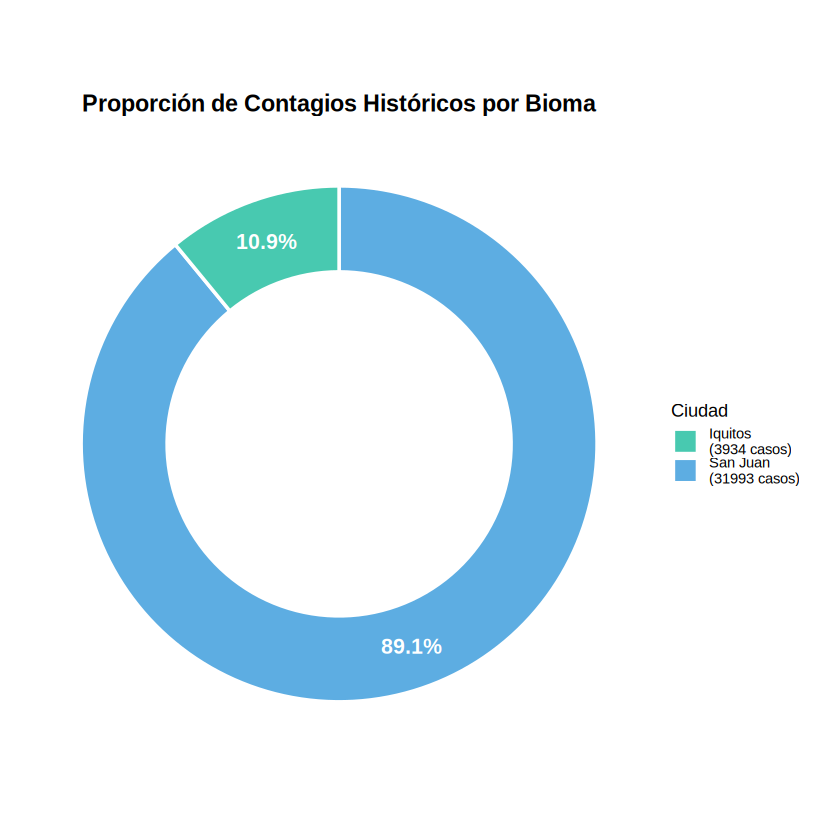


--- 3. Variabilidad Térmica (Min, Promedio, Max) ---


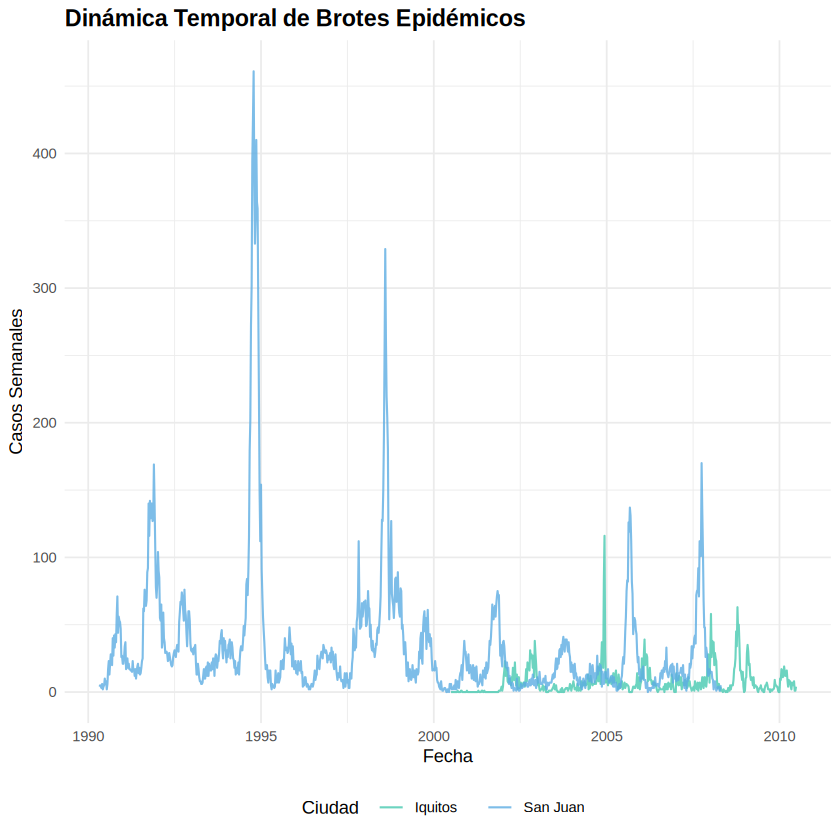

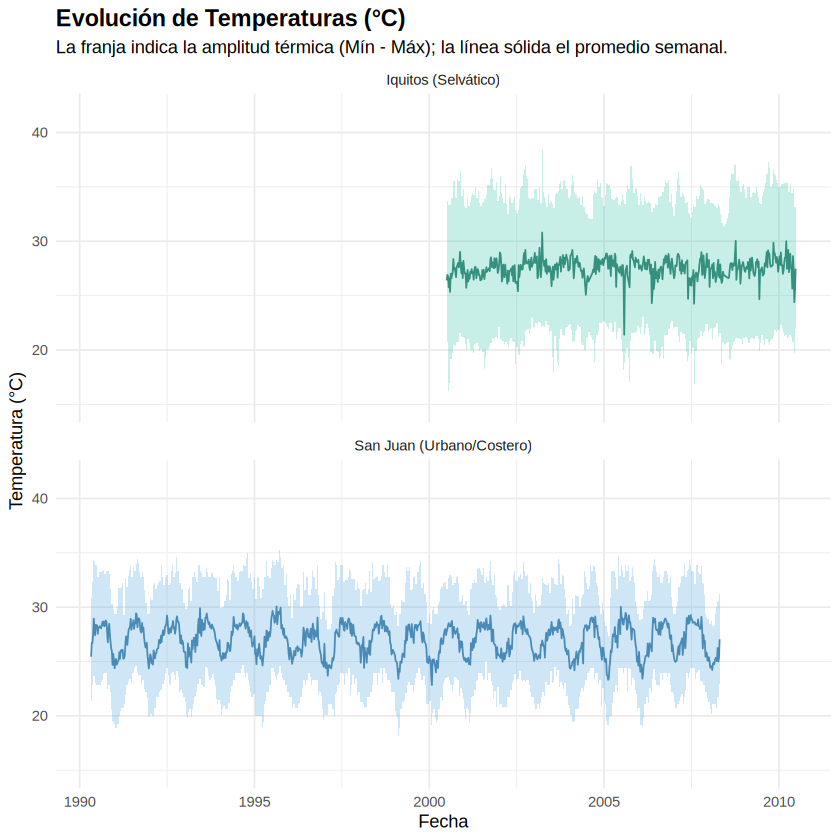

In [4]:
# Se unen temporalmente las features y labels de entrenamiento unicamente para la visualización preliminar del dataset
df_eda <- merge(train_features, train_labels, by=c("city", "year", "weekofyear"))
df_eda$fecha <- as.Date(df_eda$week_start_date)

# ---------------------------------------------------------
# --- 1. Distribución Histórica de Casos por Ciudad ---
cat("\n--- 1. Distribución Histórica de Casos por Ciudad ---\n")
casos_sj <- sum(df_eda$total_cases[df_eda$city == "sj"], na.rm = TRUE)
casos_iq <- sum(df_eda$total_cases[df_eda$city == "iq"], na.rm = TRUE)

df_pie <- data.frame(
  Ciudad = c(paste0("San Juan\n(", casos_sj, " casos)"), paste0("Iquitos\n(", casos_iq, " casos)")),
  Casos = c(casos_sj, casos_iq)
)

# Cálculos para el diagrama tipo Donut (Tarta)
df_pie$frac <- df_pie$Casos / sum(df_pie$Casos)
df_pie$ymax <- cumsum(df_pie$frac)
df_pie$ymin <- c(0, head(df_pie$ymax, n=-1))
df_pie$labelPosition <- (df_pie$ymax + df_pie$ymin) / 2
df_pie$label <- paste0(round(df_pie$frac * 100, 1), "%")

g1 <- ggplot(df_pie, aes(ymax=ymax, ymin=ymin, xmax=4, xmin=3, fill=Ciudad)) +
  geom_rect(color="white", linewidth=1) +
  coord_polar(theta="y") +
  xlim(c(1, 4)) +
  geom_text(aes(x=3.5, y=labelPosition, label=label), size=4.5, color="white", fontface="bold") +
  scale_fill_manual(values = c("#48C9B0", "#5DADE2")) +
  theme_void() +
  ggtitle("Proporción de Contagios Históricos por Bioma") +
  theme(plot.title = element_text(hjust=0.5, vjust=2, face="bold", size=14),
        legend.position="right",
        plot.margin = margin(t = 20, r = 10, b = 10, l = 10))

print(g1)

# ---------------------------------------------------------
cat("\n--- 2. Curva Epidemiológica en el Tiempo ---\n")
g2 <- ggplot(df_eda, aes(x = fecha, y = total_cases, color = city)) +
  geom_line(alpha = 0.8, linewidth = 0.6) +
  scale_color_manual(values = c("sj" = "#5DADE2", "iq" = "#48C9B0"), labels = c("sj" = "San Juan", "iq" = "Iquitos")) +
  labs(title = "Dinámica Temporal de Brotes Epidémicos", x = "Fecha", y = "Casos Semanales", color="Ciudad") +
  theme_minimal() +
  theme(plot.title = element_text(face="bold", size=14), legend.position="bottom")

print(g2)


# ---------------------------------------------------------
cat("\n--- 3. Variabilidad Térmica (Min, Promedio, Max) ---\n")
# Filtramos NA locales para evitar cortes visuales bruscos en la franja de temperaturas
df_temp <- df_eda[!is.na(df_eda$station_avg_temp_c) & !is.na(df_eda$station_min_temp_c) & !is.na(df_eda$station_max_temp_c), ]

g3 <- ggplot(df_temp, aes(x = fecha)) +
  # Franja sombreada que representa la Amplitud Térmica (Max - Min)
  geom_ribbon(aes(ymin = station_min_temp_c, ymax = station_max_temp_c, fill = city), alpha = 0.3) +
  # Línea sólida que representa la Temperatura Promedio
  geom_line(aes(y = station_avg_temp_c, color = city), linewidth=0.5, alpha=0.8) +
  facet_wrap(~city, ncol=1, labeller = as_labeller(c("sj"="San Juan (Urbano/Costero)", "iq"="Iquitos (Selvático)"))) +
  scale_color_manual(values = c("sj" = "#2874A6", "iq" = "#117864")) +
  scale_fill_manual(values = c("sj" = "#5DADE2", "iq" = "#48C9B0")) +
  labs(title = "Evolución de Temperaturas (°C)",
       subtitle = "La franja indica la amplitud térmica (Mín - Máx); la línea sólida el promedio semanal.",
       x = "Fecha", y = "Temperatura (°C)") +
  theme_minimal() +
  theme(plot.title = element_text(face="bold", size=14), legend.position="none")

print(g3)

### Conclusiones del Análisis Exploratorio (EDA)

La inspección visual del *dataset* histórico revela particularidades que fundamentan el preprocesamiento y modelado:

1.  **Asimetría Demográfica:** El **Gráfico 1** evidencia un fuerte desbalance de clases a nivel geográfico. San Juan (Puerto Rico) concentra casi el 90% (31,993 casos) del volumen total histórico de contagios frente a Iquitos (Perú). Esto justifica la necesidad metodológica de aislar ambos *datasets* (Punto 3.3) y entrenar modelos independientes, evitando que los casos de San Juan sesguen el aprendizaje sobre Iquitos.
2.  **Volatilidad Epidémica:** El **Gráfico 2** muestra la evolución temporal de la enfermedad. Se observa que San Juan experimenta brotes que superan los 400 casos semanales alrededor de 1995, mientras que Iquitos mantiene un comportamiento más estable y endémico, con picos que rara vez cruzan el umbral de los 100 casos.
3.  **Comportamiento Térmico:** El **Gráfico 3** ilustra la dinámica meteorológica subyacente. Se aprecia que San Juan posee una clara estacionalidad térmica, con abruptas en su amplitud (diferencia entre máximas y mínimas). En contraste, Iquitos, por su ubicación selvática ecuatorial, presenta temperaturas más constantes durante todo el año, pero con una amplitud térmica diaria o semanal mucho más ancha. Esta observación corrobora la pertinencia de calcular variables derivadas como el rango de temperatura y los promedios móviles (*Feature Engineering*) para ayudar al modelo a capturar estas variaciones climáticas.

## 3. Preprocesamiento e Ingeniería de Características

### 3.1. Unión de Etiquetas e Imputación Inicial (Train y Test independientes)
Se unen las *features* de entrenamiento con sus respectivas etiquetas. Los conjuntos de *Train* y *Test* se mantienen en vías separadas desde el inicio para asegurar que no exista contaminación de datos (*data leakage*).

Se analiza el porcentaje de valores nulos (NA) presentes en las mediciones de los sensores para conocer la calidad de cada conjunto de datos. Dado el carácter temporal de las series, los vacíos se imputan de forma direccional utilizando *Last Observation Carried Forward* (LOCF) y *Next Observation Carried Backward* (NOCB), conservando la linea cronológica de manera independiente.

In [5]:
# Unión de las features y labels de train
train_data <- merge(train_features, train_labels, by=c("city", "year", "weekofyear"))

# Orden cronológico estricto por ciudad en ambos datasets
setorder(train_data, city, year, weekofyear)
setorder(test_features, city, year, weekofyear)

# Definición de las columnas numéricas ambientales
cols_climaticas <- setdiff(names(train_data), c("city", "year", "weekofyear", "week_start_date", "total_cases"))

# Evaluación de la cantidad de NA antes de imputar en el set de entrenamiento
total_val_train <- nrow(train_data) * length(cols_climaticas)
na_train <- sum(is.na(train_data[, ..cols_climaticas]))
pct_na_train <- round((na_train / total_val_train) * 100, 2)

# Evaluación de la cantidad de NA antes de imputar en el set de testeo
total_val_test <- nrow(test_features) * length(cols_climaticas)
na_test <- sum(is.na(test_features[, ..cols_climaticas]))
pct_na_test <- round((na_test / total_val_test) * 100, 2)

cat("\n--- Diagnóstico de Valores Nulos (NA) ---\n")
cat("Train Set: ", na_train, " NA de ", total_val_train, " observaciones climáticas (", pct_na_train, "%)\n", sep="")
cat("Test Set : ", na_test, " NA de ", total_val_test, " observaciones climáticas (", pct_na_test, "%)\n\n", sep="")

# Imputación en Train
train_data[, (cols_climaticas) := lapply(.SD, function(x) na.locf(x, na.rm=FALSE)), by=city, .SDcols=cols_climaticas]
train_data[, (cols_climaticas) := lapply(.SD, function(x) na.locf(x, fromLast=TRUE, na.rm=FALSE)), by=city, .SDcols=cols_climaticas]

# Imputación en Test
test_features[, (cols_climaticas) := lapply(.SD, function(x) na.locf(x, na.rm=FALSE)), by=city, .SDcols=cols_climaticas]
test_features[, (cols_climaticas) := lapply(.SD, function(x) na.locf(x, fromLast=TRUE, na.rm=FALSE)), by=city, .SDcols=cols_climaticas]

cat("Imputación de NA completa en ambos conjuntos.\n")


--- Diagnóstico de Valores Nulos (NA) ---
Train Set: 548 NA de 29120 observaciones climáticas (1.88%)
Test Set : 119 NA de 8320 observaciones climáticas (1.43%)

Imputación de NA completa en ambos conjuntos.


### 3.2. Feature Engineering

La dinámica de transmisión del dengue no es lineal ni inmediata; está biológicamente retrasada por la suma del Período de Incubación Extrínseco (desarrollo viral en el mosquito) y el Período Intrínseco (en el humano). Como demostraron Sánchez-Lara et al. (2022) y Mussumeci & Coelho (2020), correlacionar la incidencia del dengue con variables climáticas de la misma semana ignora esta latencia y disminuye la capacidad predictiva.

Basándonos en la bibliografía epidemiológica reciente (Liu et al., 2023; Reinhold et al., 2018), que evidencia cómo las variaciones térmicas aceleran el metabolismo del vector *Aedes aegypti*, se diseñó una función modular para enriquecer la matriz de datos original. Esta función incorpora:

*   **Derivadas Clínicas Inmediatas:** Amplitud térmica semanal (estrés térmico sobre la población de mosquitos) e Índice de Vegetación (NDVI) promedio espacial (proxy de la cobertura vegetal y retención de humedad).
*   **Retardos Temporales (Lags):** Desplazamiento de las variables climáticas entre 1 y 4 semanas retrospectivas para simular matemáticamente el ciclo de incubación dual del virus.
*   **Deltas:** Tasa de cambio respecto a la semana anterior para detectar alteraciones climáticas bruscas, fundamentales para la eclosión de reservorios acuáticos (Meza-Ballesta, 2014).
*   **Promedios Móviles:** Ventanas de 4 y 8 semanas para extraer tendencias estacionales acumulativas y suavizar el ruido atmosférico (estocástico) propio de los *datasets* meteorológicos.

In [6]:
# Definición de función modular para Feature Engineering
engineer_dengue_features <- function(dt, cols_base) {

  # 1. Creación de métricas derivadas inmediatas
  # Crea una nueva columna llamada temp_rango (que corresponde a la amplitud térmica) y una que calcula el promedio para esa semana del Indice de Vegetación (ndvi) a partir de los 4 valores aportados en el dataset.
  dt[, temp_rango := station_max_temp_c - station_min_temp_c]
  dt[, ndvi_promedio := rowMeans(cbind(ndvi_ne, ndvi_nw, ndvi_se, ndvi_sw), na.rm=TRUE)]

  cols_a_laguear <- c(cols_base, "temp_rango", "ndvi_promedio")

  # 2. Retardos temporales (1 a 4 semanas)
  # Crea una copia del valor de esa variable pero desplazada 1 semana, 2, 3 y 4 semanas hacia atrás en el tiempo... tiempo del vector biológico
  for(l in 1:4) {
    dt[, paste0(cols_a_laguear, "_lag", l) := shift(.SD, l, type="lag"), by=city, .SDcols=cols_a_laguear]
  }

  # 3. Deltas semanales (respecto a la semana anterior)
  # Calcula la diferencia entre el valor y lag1
  for(col in cols_a_laguear) {
    dt[, paste0(col, "_delta1") := get(col) - get(paste0(col, "_lag1"))]
  }

  # 4. Promedios Móviles (Ventanas de 4 y 8 semanas)
  # Promedios Móviles (Tendencias de 4 y 8 semanas), son los promedios en ventana movil (para estudiar efecto acumulativo)
  for(col in cols_a_laguear) {
    dt[, paste0(col, "_rmean4") := frollmean(get(col), 4, align="right", na.rm=TRUE), by=city]
    dt[, paste0(col, "_rmean8") := frollmean(get(col), 8, align="right", na.rm=TRUE), by=city]
  }

  # 5. Segunda pasada de imputación para los NA generados en los saltos temporales
  # Se vuelve a aplicar LOCF y NOCB en todas las columnas que tengan NA
  # porque los promedios moviles, los lags y los delta generarán NA cuando el periodo de cálculo exceda el disponible en la base
  # Si hay NA va a fallar SVM
  cols_todas <- setdiff(names(dt), c("city", "year", "weekofyear", "week_start_date", "total_cases"))
  dt[, (cols_todas) := lapply(.SD, function(x) na.locf(na.locf(x, na.rm=FALSE), fromLast=TRUE, na.rm=FALSE)), by=city, .SDcols=cols_todas]

  # Eliminar week_start_date porque no es numérica y es redundante con la semana y el año que ya está presente
  dt[, week_start_date := NULL]

  return(dt)
}

# Ejecución de la función sobre ambos datasets de manera independiente
cat("Aplicando Feature Engineering en Train...\n")
train_data <- engineer_dengue_features(train_data, cols_climaticas)

cat("Aplicando Feature Engineering en Test...\n")
test_features <- engineer_dengue_features(test_features, cols_climaticas)

cat("Feature Engineering completo en ambos conjuntos.\n")

Aplicando Feature Engineering en Train...
Aplicando Feature Engineering en Test...
Feature Engineering completo en ambos conjuntos.


### 3.3. Separación Geográfica

Los biomas de San Juan (isla tropical costera) e Iquitos (selva amazónica) presentan comportamientos a priori distintos. Tras haber calculado los retardos, se separan los conjuntos de entrenamiento y prueba de manera aislada por ciudad.

A continuación, se imprimen en pantalla las dimensiones resultantes para validar que la segmentación de los datos sea la correcta antes de proceder al entrenamiento.

In [7]:
# Segregación por bioma (Ciudad) para Entrenamiento
train_sj <- train_data[city == "sj"]
train_iq <- train_data[city == "iq"]

# Segregación por bioma (Ciudad) para Prueba
test_sj <- test_features[city == "sj"]
test_iq <- test_features[city == "iq"]

cat("\n--- Dimensiones de los Datasets ---\n")
cat("San Juan - Train:", nrow(train_sj), "filas | Test:", nrow(test_sj), "filas\n")
cat("Iquitos  - Train:", nrow(train_iq), "filas | Test:", nrow(test_iq), "filas\n\n")

pct_sj <- round((nrow(train_sj) / nrow(train_data)) * 100, 1)
pct_iq <- round((nrow(train_iq) / nrow(train_data)) * 100, 1)
cat("Distribución del Train Set: San Juan representa el", pct_sj, "% de los datos históricos e Iquitos el", pct_iq, "%.\n")


--- Dimensiones de los Datasets ---
San Juan - Train: 936 filas | Test: 260 filas
Iquitos  - Train: 520 filas | Test: 156 filas

Distribución del Train Set: San Juan representa el 64.3 % de los datos históricos e Iquitos el 35.7 %.


## 4. Modelo 1: Ensambles de Árboles (LightGBM)

Utilizamos `LightGBM` (*Light Gradient Boosting Machine*) como modelo de referencia (*baseline*) debido a su capacidad para manejar valores atípicos y no linealidades.

### Parametrización y Optimización
Para evitar el sobreajuste (*overfitting*) provocado por la alta dimensionalidad de los datos tras el *Feature Engineering*, se configura el modelo con los siguientes hiperparámetros a optimizar:
*   **`learning_rate`:** Modula el tamaño del paso en el descenso de gradiente (optimizado entre 0.01 y 0.15).
*   **`num_leaves`:** Define la complejidad máxima del árbol (optimizado entre 15 y 63 hojas).
*   **`feature_fraction`:** Selecciona un subconjunto de características aleatorias por iteración para añadir robustez.
*   **`bagging_fraction`:** Selecciona un subconjunto de datos por iteración para evitar memorización.

Se ejecuta una **Optimización Bayesiana** empleando Validación Cruzada temporal. Si la configuración óptima ya fue determinada previamente, el sistema la recupera desde un archivo local para agilizar el cómputo.

In [8]:
# Preparar Matrices para LightGBM
features_lgb <- setdiff(names(train_sj), c("city", "year", "weekofyear", "total_cases"))

dtrain_sj <- lgb.Dataset(data = as.matrix(train_sj[, ..features_lgb]), label = train_sj$total_cases)
dtrain_iq <- lgb.Dataset(data = as.matrix(train_iq[, ..features_lgb]), label = train_iq$total_cases)

# Si ya se hizo antes toma el resultado con los mejores hiperparametros que se guardó en un .txt (para reducir tiempo de procesamiento más que nada)
archivo_params <- "mejores_parametros_lgb.txt"

if (file.exists(archivo_params)) {
  cat("¡Archivo de parámetros encontrado! Cargando configuración...\n")

  # Lee archivo y extrae valores
  lineas <- readLines(archivo_params)
  parametros <- list(
    objective = "regression_l1",
    metric = "mae",
    verbosity = -1,
    bagging_freq = 5
  )

  for(linea in lineas) {
    partes <- strsplit(linea, "=")[[1]]
    if(length(partes) == 2) {
      parametros[[partes[1]]] <- as.numeric(partes[2])
    }
  }
  if(!is.null(parametros$num_leaves)) parametros$num_leaves <- as.integer(parametros$num_leaves)

} else {

  # Si no está el archivo con los parámetros, inicia la optimización bayesiana....
  cat("No se encontró archivo de parámetros. Iniciando Optimización Bayesiana (este proceso tarda...)\n")

  # DEFINIR FUNCIÓN DE EVALUACIÓN
  # rBayesianOptimization siempre busca MAXIMIZAR.
  lgb_eval_fun <- function(learning_rate, num_leaves, feature_fraction, bagging_fraction) {

    pars <- list(
      objective = "regression_l1",
      metric = "mae",
      learning_rate = learning_rate,
      num_leaves = as.integer(num_leaves),
      feature_fraction = feature_fraction,
      bagging_fraction = bagging_fraction,
      bagging_freq = 5,
      verbosity = -1
    )

    # Usamos Validación Cruzada (CV) sobre San Juan para encontrar los mejores parámetros
    cv_modelo <- lgb.cv(
      params = pars,
      data = dtrain_sj,
      nrounds = 200,          # Límite de árboles
      nfold = 3,              # 3 particiones
      early_stopping_rounds = 20, # Frena si no mejora en 20 iteraciones
      showsd = FALSE
    )

    mejor_mae <- cv_modelo$best_score
    return(list(Score = -mejor_mae, Pred = 0))
  }

  # Definir los límites de busqueda (Bounds)
  limites <- list(
    learning_rate = c(0.01, 0.15),
    num_leaves = c(15L, 63L),  # L es porque es un rango de números enteros
    feature_fraction = c(0.5, 1.0),
    bagging_fraction = c(0.5, 1.0)
  )

  # EJECUCION DE LA OPTIMIZACION
  set.seed(42)
  opt_res <- BayesianOptimization(
    lgb_eval_fun,
    bounds = limites,
    init_points = 5,  # Puntos aleatorios iniciales
    n_iter = 15,      # numero de iteraciones de búsqueda
    acq = "ucb"
  )

  # Lista con los mejores parámetros
  mejores_pars <- opt_res$Best_Par
  parametros <- list(
    objective = "regression_l1",
    metric = "mae",
    learning_rate = mejores_pars["learning_rate"],
    num_leaves = as.integer(mejores_pars["num_leaves"]),
    feature_fraction = mejores_pars["feature_fraction"],
    bagging_fraction = mejores_pars["bagging_fraction"],
    bagging_freq = 5,
    verbosity = -1
  )

  # Guarda los resultados en un .txt para no volver a correrlo si ya se dispone de los resultados.
  cat("¡Optimización finalizada! Guardando los mejores parámetros en:", archivo_params, "\n")
  lineas_guardar <- c(
    paste0("learning_rate=", parametros$learning_rate),
    paste0("num_leaves=", parametros$num_leaves),
    paste0("feature_fraction=", parametros$feature_fraction),
    paste0("bagging_fraction=", parametros$bagging_fraction)
  )
  writeLines(lineas_guardar, archivo_params)
}

cat("\n--- Parámetros Finales para LightGBM ---\n")
cat("Learning Rate:", parametros$learning_rate, "\n")
cat("Num Leaves:", parametros$num_leaves, "\n")
cat("Feature Fraction:", parametros$feature_fraction, "\n")
cat("Bagging Fraction:", parametros$bagging_fraction, "\n\n")

¡Archivo de parámetros encontrado! Cargando configuración...

--- Parámetros Finales para LightGBM ---
Learning Rate: 0.08192115 
Num Leaves: 22 
Feature Fraction: 0.751993 
Bagging Fraction: 1 



### 4.1. Entrenamiento y evaluación interna (LightGBM)
Se procede al entrenamiento definitivo de los modelos para ambas ciudades utilizando los hiperparámetros óptimos, y se evalúa el Error Absoluto Medio (MAE) sobre el propio set de entrenamiento.

In [9]:

# Entrenamiento con los parámetros
cat("\nEntrenando los modelos con los parámetros óptimos...\n")

modelo_sj <- lgb.train(params = parametros, data = dtrain_sj, nrounds = 300)
modelo_iq <- lgb.train(params = parametros, data = dtrain_iq, nrounds = 300)

cat("¡Modelos entrenados! Evaluando métrica interna MAE estimada en Train...\n")
pred_train_sj <- predict(modelo_sj, as.matrix(train_sj[, ..features_lgb]))
mae_sj <- mean(abs(train_sj$total_cases - pred_train_sj))
cat(">> MAE Interno San Juan estimado:", round(mae_sj, 2), "\n")

pred_train_iq <- predict(modelo_iq, as.matrix(train_iq[, ..features_lgb]))
mae_iq <- mean(abs(train_iq$total_cases - pred_train_iq))
cat(">> MAE Interno Iquitos estimado:", round(mae_iq, 2), "\n")


Entrenando los modelos con los parámetros óptimos...
¡Modelos entrenados! Evaluando métrica interna MAE estimada en Train...
>> MAE Interno San Juan estimado: 9.42 
>> MAE Interno Iquitos estimado: 2.15 


### 4.2. Predicción y exportación (LightGBM)
Se generan las predicciones finales sobre el conjunto de prueba (`Test Set`). Debido a la naturaleza de los datos epidemiológicos, se aplica un control para evitar predicciones con valores de casos negativos antes de exportar el archivo CSV final.

In [10]:
# Predicción Final
cat("Generando predicciones finales...\n")
pred_test_sj <- round(predict(modelo_sj, as.matrix(test_sj[, ..features_lgb])))
pred_test_iq <- round(predict(modelo_iq, as.matrix(test_iq[, ..features_lgb])))

test_sj$total_cases <- ifelse(pred_test_sj < 0, 0, pred_test_sj)
test_iq$total_cases <- ifelse(pred_test_iq < 0, 0, pred_test_iq)

sub_lgb <- rbindlist(list(test_sj[, .(city, year, weekofyear, total_cases)],
                          test_iq[, .(city, year, weekofyear, total_cases)]))

Generando predicciones finales...


In [11]:
# Exportación
molde <- fread(paste0(DATA_PATH_INPUT,"submission_format.csv"))
molde[sub_lgb, total_cases := i.total_cases, on=.(city, year, weekofyear)]
molde[is.na(total_cases), total_cases := 0]

fwrite(molde, paste0(DATA_PATH_OUTPUT,"../output/submission_lightgbm.csv"))
cat("Archivo 'submission_lightgbm.csv' creado.\n")

Archivo 'submission_lightgbm.csv' creado.


## 5. Modelo 2: Máquinas de Vectores de Soporte (SVM)

A diferencia de los ensambles de árboles, las Máquinas de Vectores de Soporte (SVM) basan su cálculo en la optimización de hiperplanos utilizando un *Kernel Radial* (RBF) para separar los datos no lineales en espacios de alta dimensionalidad. Debido a la naturaleza del modelo, requiere que las variables de entrada se estandarizan internamente (`scale = TRUE`).

### Parametrización y Búsqueda en Cuadrícula
Para este modelo, implementamos una búsqueda exhaustiva (*Grid Search*) enfocada en dos hiperparámetros críticos:
*   **`cost` ($C$):** Penaliza los errores de estimación. Un valor alto ajusta estrictamente el margen a los datos (riesgo de *overfitting*), mientras que un valor bajo flexibiliza el límite de decisión. (Se evalúan valores: 0.1, 1, 10, 50).
*   **`gamma` ($\gamma$):** Define el alcance de influencia de un solo ejemplo de entrenamiento en el *Kernel Radial*. Valores más bajos implican un alcance más amplio. (Se evalúan valores: 0.01, 0.05, 0.1).

Las matrices de entrenamiento se evalúan cronológicamente para evitar la contaminación temporal (*look-ahead bias*).

In [12]:
cat("\n--- Entrenando Modelo 2: SVM ---\n")

archivo_params_svm <- "mejores_parametros_svm.txt"

# Definimos las columnas predictoras (excluyendo variables de control y objetivo)
features_model <- setdiff(names(train_sj), c("city", "year", "weekofyear", "total_cases"))

if (file.exists(archivo_params_svm)) {
  cat("¡Archivo de parámetros SVM encontrado! Cargando configuración guardada...\n")

  # Carga parámetros desde el archivo
  lineas_svm <- readLines(archivo_params_svm)
  p_svm <- list()
  for(linea in lineas_svm) {
    partes <- strsplit(linea, "=")[[1]]
    if(length(partes) == 2) p_svm[[partes[1]]] <- as.numeric(partes[2])
  }

  # Entrena modelo con parámetros guardados
  modelo_svm_sj <- svm(x = as.matrix(train_sj[, ..features_model]),
                       y = train_sj$total_cases,
                       type = "eps-regression", kernel = "radial", scale = TRUE,
                       cost = p_svm$cost_sj, gamma = p_svm$gamma_sj)

  modelo_svm_iq <- svm(x = as.matrix(train_iq[, ..features_model]),
                       y = train_iq$total_cases,
                       type = "eps-regression", kernel = "radial", scale = TRUE,
                       cost = p_svm$cost_iq, gamma = p_svm$gamma_iq)

  cat("Modelos San Juan e Iquitos entrenados con parámetros óptimos cargados.\n")

} else {
  cat("No se encontró archivo de parámetros SVM. Iniciando Grid Search (esto puede tardar)...\n")

  # Optimización para San Juan
  cat("Optimizando San Juan...\n")
  tune_sj <- tune(svm, train.x = as.matrix(train_sj[, ..features_model]), train.y = train_sj$total_cases,
                  type = "eps-regression", kernel = "radial", scale = TRUE,
                  ranges = list(cost = c(0.1, 1, 10, 50), gamma = c(0.01, 0.05, 0.1)))
  modelo_svm_sj <- tune_sj$best.model

  # Optimización para Iquitos
  cat("Optimizando Iquitos...\n")
  tune_iq <- tune(svm, train.x = as.matrix(train_iq[, ..features_model]), train.y = train_iq$total_cases,
                  type = "eps-regression", kernel = "radial", scale = TRUE,
                  ranges = list(cost = c(0.1, 1, 10, 50), gamma = c(0.01, 0.05, 0.1)))
  modelo_svm_iq <- tune_iq$best.model

  # Guarda resultados en .txt
  cat("Guardando mejores parámetros en:", archivo_params_svm, "\n")
  lineas_guardar_svm <- c(
    paste0("cost_sj=", modelo_svm_sj$cost),
    paste0("gamma_sj=", modelo_svm_sj$gamma),
    paste0("cost_iq=", modelo_svm_iq$cost),
    paste0("gamma_iq=", modelo_svm_iq$gamma)
  )
  writeLines(lineas_guardar_svm, archivo_params_svm)
}

cat("\n--- Parámetros Finales para SVM ---\n")
cat("San Juan -> Cost:", p_svm$cost_sj %||% modelo_svm_sj$cost, "| Gamma:", p_svm$gamma_sj %||% modelo_svm_sj$gamma, "\n")
cat("Iquitos  -> Cost:", p_svm$cost_iq %||% modelo_svm_iq$cost, "| Gamma:", p_svm$gamma_iq %||% modelo_svm_iq$gamma, "\n\n")


--- Entrenando Modelo 2: SVM ---
¡Archivo de parámetros SVM encontrado! Cargando configuración guardada...
Modelos San Juan e Iquitos entrenados con parámetros óptimos cargados.

--- Parámetros Finales para SVM ---
San Juan -> Cost: 10 | Gamma: 0.01 
Iquitos  -> Cost: 1 | Gamma: 0.01 



### 5.1. Evaluación y predicción (SVM)
De la misma manera que con el modelo anterior, se evalúa el MAE interno y se generan las predicciones finales con control de negativos para su posterior exportación.

In [13]:

# Evaluación interna MAE
pred_train_svm_sj <- predict(modelo_svm_sj, as.matrix(train_sj[, ..features_model]))
pred_train_svm_iq <- predict(modelo_svm_iq, as.matrix(train_iq[, ..features_model]))

cat("\n>> MAE Interno SVM San Juan:", round(mean(abs(train_sj$total_cases - pred_train_svm_sj)), 2), "\n")
cat(">> MAE Interno SVM Iquitos:", round(mean(abs(train_iq$total_cases - pred_train_svm_iq)), 2), "\n")

# Predicción sobre el Test Set con redondeo y control de negativos
pred_test_svm_sj <- round(predict(modelo_svm_sj, as.matrix(test_sj[, ..features_model])))
pred_test_svm_sj <- ifelse(pred_test_svm_sj < 0, 0, pred_test_svm_sj)

pred_test_svm_iq <- round(predict(modelo_svm_iq, as.matrix(test_iq[, ..features_model])))
pred_test_svm_iq <- ifelse(pred_test_svm_iq < 0, 0, pred_test_svm_iq)

cat("SVM completado!\n")


>> MAE Interno SVM San Juan: 4.84 
>> MAE Interno SVM Iquitos: 2.74 
SVM completado!


In [14]:
# Exportación de resultados
cat("\nGenerando archivo de Submission SVM...\n")

sub_svm <- rbindlist(list(
  test_sj[, .(city, year, weekofyear, total_cases = pred_test_svm_sj)],
  test_iq[, .(city, year, weekofyear, total_cases = pred_test_svm_iq)]
))

molde <- fread(paste0(DATA_PATH_INPUT,"submission_format.csv"))
molde[sub_svm, total_cases := i.total_cases, on=.(city, year, weekofyear)]
molde[is.na(total_cases), total_cases := 0]

fwrite(molde, paste0(DATA_PATH_OUTPUT,"../output/submission_svm.csv"))
cat("Archivo 'submission_svm.csv' creado.\n")


Generando archivo de Submission SVM...
Archivo 'submission_svm.csv' creado.


## 6. Modelo 3: Redes Neuronales Artificiales (ANN con Torch)

## 6. Modelo 3: Redes Neuronales Artificiales (ANN con Torch)

Se implementa una arquitectura de Aprendizaje Profundo (*Deep Learning*) mediante la librería nativa de R `torch` y su *wrapper* `luz`. Dado que el descenso de gradiente es sensible a la escala de las entradas, se aplican dos transformaciones previas al modelado:

*   **Estandarización de las *features* (z-score):** Cada variable predictora se centra y escala con la media y el desvío estándar calculados exclusivamente sobre el conjunto de entrenamiento. Esos mismos parámetros se aplican al conjunto de prueba, evitando la contaminación de datos (*data leakage*) y garantizando que ambos conjuntos compartan la misma escala.
*   **Transformación logarítmica de la variable objetivo (`log1p`):** La distribución de `total_cases` es asimétrica, con brotes que superan los 400 casos semanales. La transformación $\log(1 + y)$ comprime los picos epidémicos y distribuye la señal de forma más homogénea, evitando que la red colapse hacia una predicción constante.

### Arquitectura y Parametrización
La red se diseña como un Perceptrón Multicapa (MLP) configurado de la siguiente manera:
*   **Arquitectura Base:** Capa de entrada conectada a dos capas ocultas con función de activación no lineal `ReLU`, y una capa de salida lineal de un solo nodo (para regresión).
*   **Función de Pérdida:** Se utiliza el Error Cuadrático Medio (MSE) sobre la escala logarítmica, que penaliza las desviaciones grandes.
*   **Prevención de Sobreajuste:** Se integra una capa de `Dropout` después de cada capa oculta, con una tasa entre 0 y 0.3.
*   **Capacidad de la Red:** El número de neuronas por capa (`nodes1`, `nodes2`) se ajusta mediante el optimizador, con rangos moderados acordes al volumen de datos disponible (936 semanas en San Juan y 520 en Iquitos).
*   **Optimizador y Aprendizaje:** Se utiliza el algoritmo *Adam* con una tasa de aprendizaje (`lr`) optimizada. El entrenamiento se detiene tempranamente (`early_stopping`) si el error de validación no mejora tras 20 iteraciones, conservando los pesos del mejor modelo encontrado.

In [15]:
# MODELO 3 Redes Neuronales Artificiales - ANN

# Copias independientes para la normalización
train_sj_nn <- copy(train_sj)
test_sj_nn  <- copy(test_sj)
train_iq_nn <- copy(train_iq)
test_iq_nn  <- copy(test_iq)

cols_todas <- setdiff(names(train_sj_nn), c("city", "year", "weekofyear", "week_start_date", "total_cases"))

# Estandarización z-score con media y desvío del TRAIN, aplicados igual al TEST
escalar_con_train <- function(train, test, cols) {
  for (c in cols) {
    mu <- mean(train[[c]], na.rm = TRUE)
    s  <- sd(train[[c]], na.rm = TRUE)
    if (is.na(s) || s == 0) s <- 1
    set(train, j = c, value = (train[[c]] - mu) / s)
    set(test,  j = c, value = (test[[c]]  - mu) / s)
  }
}
escalar_con_train(train_sj_nn, test_sj_nn, cols_todas)
escalar_con_train(train_iq_nn, test_iq_nn, cols_todas)

# Variable objetivo en escala logarítmica (se revierte con expm1 al predecir)
y_train_sj <- log1p(train_sj_nn$total_cases)
y_train_iq <- log1p(train_iq_nn$total_cases)

# Definición de las features excluyendo las variables de control y la objetivo
features_model <- setdiff(names(train_sj_nn), c("city", "year", "weekofyear", "total_cases", "week_start_date"))
num_inputs <- length(features_model)

x_train_sj <- as.matrix(train_sj_nn[, ..features_model])
x_train_iq <- as.matrix(train_iq_nn[, ..features_model])
x_test_sj  <- as.matrix(test_sj_nn[, ..features_model])
x_test_iq  <- as.matrix(test_iq_nn[, ..features_model])

### 6.1. Arquitectura de la Red y Optimización Bayesiana

Se define la arquitectura del Perceptrón Multicapa (MLP) utilizando la librería `torch`. Los hiperparámetros (nodos por capa, tasa de aprendizaje y *dropout*) se optimizan mediante Optimización Bayesiana de forma independiente para cada ciudad, dado que San Juan e Iquitos presentan escalas y dinámicas epidémicas muy distintas.

Para respetar el carácter cronológico de la serie, la validación es temporal: el 80% inicial de las semanas se utiliza para entrenar y el 20% final para validar. La función objetivo del optimizador es el Error Absoluto Medio (MAE) sobre el bloque de validación, expresado en casos reales tras revertir la transformación logarítmica.

Si la búsqueda ya fue completada con anterioridad, los parámetros óptimos se recuperan desde un archivo local para agilizar el cómputo.

In [16]:
# Tensores completos (para predecir sobre train y test)
x_sj_t      <- torch_tensor(x_train_sj, dtype = torch_float32())
x_iq_t      <- torch_tensor(x_train_iq, dtype = torch_float32())
x_test_sj_t <- torch_tensor(x_test_sj,  dtype = torch_float32())
x_test_iq_t <- torch_tensor(x_test_iq,  dtype = torch_float32())

# Arquitectura de la red (MLP)
dengue_mlp <- nn_module(
  "DengueMLP",
  initialize = function(num_inputs, nodes1, nodes2, drop_rate) {
    self$fc1   <- nn_linear(num_inputs, as.integer(nodes1))
    self$drop1 <- nn_dropout(drop_rate)
    self$fc2   <- nn_linear(as.integer(nodes1), as.integer(nodes2))
    self$drop2 <- nn_dropout(drop_rate)
    self$out   <- nn_linear(as.integer(nodes2), 1)
  },
  forward = function(x) {
    x %>%
      self$fc1() %>% nnf_relu() %>% self$drop1() %>%
      self$fc2() %>% nnf_relu() %>% self$drop2() %>%
      self$out()
  }
)

# Entrenamiento con validación TEMPORAL (últimas 20% semanas), pérdida MSE
# y conservación del mejor modelo según la pérdida de validación
entrenar_mlp <- function(x, y, nodes1, nodes2, dropout, lr, epochs = 300) {
  torch_manual_seed(42)
  n <- nrow(x); corte <- floor(n * 0.8)
  x_tr <- torch_tensor(x[1:corte, , drop = FALSE], dtype = torch_float32())
  y_tr <- torch_tensor(matrix(y[1:corte], ncol = 1), dtype = torch_float32())
  x_va <- torch_tensor(x[(corte + 1):n, , drop = FALSE], dtype = torch_float32())
  y_va <- torch_tensor(matrix(y[(corte + 1):n], ncol = 1), dtype = torch_float32())

  dengue_mlp %>%
    setup(loss = nn_mse_loss(), optimizer = optim_adam) %>%
    set_hparams(num_inputs = num_inputs, nodes1 = as.integer(nodes1),
                nodes2 = as.integer(nodes2), drop_rate = dropout) %>%
    set_opt_hparams(lr = lr) %>%
    fit(
      data       = list(x_tr, y_tr),
      valid_data = list(x_va, y_va),
      epochs     = epochs,
      dataloader_options = list(batch_size = 32, shuffle = TRUE),
      callbacks = list(
        luz_callback_early_stopping(monitor = "valid_loss", patience = 20),
        luz_callback_keep_best_model(monitor = "valid_loss")
      ),
      verbose = FALSE
    )
}

# Función objetivo: MAE en casos reales sobre el bloque de validación temporal
crear_eval_fun <- function(x, y) {
  function(nodes1, nodes2, dropout, lr) {
    modelo <- entrenar_mlp(x, y, nodes1, nodes2, dropout, lr, epochs = 150)
    n <- nrow(x); corte <- floor(n * 0.8)
    x_va <- torch_tensor(x[(corte + 1):n, , drop = FALSE], dtype = torch_float32())
    pred <- pmax(expm1(as.numeric(predict(modelo, x_va))), 0)
    real <- expm1(y[(corte + 1):n])
    list(Score = -mean(abs(real - pred)), Pred = 0)
  }
}

limites_torch <- list(
  nodes1  = c(32L, 128L),   # menos neuronas: hay pocas filas (936 / 520)
  nodes2  = c(8L, 64L),
  dropout = c(0.0, 0.3),    # el dropout alto contribuye al colapso
  lr      = c(0.0005, 0.005)
)

optimizar_ciudad <- function(x, y) {
  set.seed(42)
  res <- BayesianOptimization(crear_eval_fun(x, y), bounds = limites_torch,
                              init_points = 5, n_iter = 10, acq = "ucb")
  b <- res$Best_Par
  list(nodes1 = as.integer(b["nodes1"]), nodes2 = as.integer(b["nodes2"]),
       dropout = unname(b["dropout"]), lr = unname(b["lr"]))
}

# Archivo nuevo (v2) para no reutilizar los parámetros de la versión anterior
archivo_params_torch <- "mejores_parametros_torch_v2.txt"

if (file.exists(archivo_params_torch)) {
  cat("¡Archivo de parámetros Torch encontrado! Cargando configuración guardada...\n")
  lineas_t <- readLines(archivo_params_torch)
  vals <- setNames(as.numeric(sub(".*=", "", lineas_t)), sub("=.*", "", lineas_t))
  leer <- function(pref) list(nodes1 = as.integer(vals[paste0(pref, "_nodes1")]),
                              nodes2 = as.integer(vals[paste0(pref, "_nodes2")]),
                              dropout = unname(vals[paste0(pref, "_dropout")]),
                              lr = unname(vals[paste0(pref, "_lr")]))
  p_t_sj <- leer("sj")
  p_t_iq <- leer("iq")
} else {
  cat("No se encontró archivo. Iniciando Optimización Bayesiana por ciudad...\n")
  cat("Optimizando San Juan...\n");  p_t_sj <- optimizar_ciudad(x_train_sj, y_train_sj)
  cat("Optimizando Iquitos...\n");   p_t_iq <- optimizar_ciudad(x_train_iq, y_train_iq)

  guardar <- function(p, pref) paste0(pref, "_", names(p), "=", unlist(p))
  writeLines(c(guardar(p_t_sj, "sj"), guardar(p_t_iq, "iq")), archivo_params_torch)
  cat("Parámetros guardados en:", archivo_params_torch, "\n")
}

cat("\n--- Parámetros Finales para Red Neuronal (Torch) ---\n")
cat("San Juan -> Nodos:", p_t_sj$nodes1, "/", p_t_sj$nodes2,
    "| Dropout:", round(p_t_sj$dropout, 3), "| LR:", signif(p_t_sj$lr, 3), "\n")
cat("Iquitos  -> Nodos:", p_t_iq$nodes1, "/", p_t_iq$nodes2,
    "| Dropout:", round(p_t_iq$dropout, 3), "| LR:", signif(p_t_iq$lr, 3), "\n\n")

No se encontró archivo. Iniciando Optimización Bayesiana por ciudad...
Optimizando San Juan...
elapsed = 13.021	Round = 1	nodes1 = 120.0000	nodes2 = 37.0000	dropout = 0.1373225	lr = 0.004730065	Value = -16.21233 
elapsed = 13.441	Round = 2	nodes1 = 122.0000	nodes2 = 49.0000	dropout = 0.2157337	lr = 0.004902019	Value = -17.43873 
elapsed = 27.975	Round = 3	nodes1 = 59.0000	nodes2 = 16.0000	dropout = 0.2804017	lr = 0.001028693	Value = -15.78272 
elapsed = 13.182	Round = 4	nodes1 = 112.0000	nodes2 = 45.0000	dropout = 0.07662865	lr = 0.002637487	Value = -18.00443 
elapsed = 14.891	Round = 5	nodes1 = 94.0000	nodes2 = 47.0000	dropout = 0.1386878	lr = 0.003021497	Value = -18.54366 
elapsed = 15.345	Round = 6	nodes1 = 34.0000	nodes2 = 11.0000	dropout = 0.2517268	lr = 0.003363085	Value = -16.76671 
elapsed = 19.638	Round = 7	nodes1 = 114.0000	nodes2 = 21.0000	dropout = 0.007454397	lr = 0.0005394809	Value = -17.89535 
elapsed = 20.731	Round = 8	nodes1 = 125.0000	nodes2 = 20.0000	dropout = 0.3000

In [17]:
# Entrenamiento de la red (parámetros propios de cada ciudad)
cat("\nEntrenando Red Neuronal...\n")

model_sj_torch <- entrenar_mlp(x_train_sj, y_train_sj, p_t_sj$nodes1, p_t_sj$nodes2, p_t_sj$dropout, p_t_sj$lr)
model_iq_torch <- entrenar_mlp(x_train_iq, y_train_iq, p_t_iq$nodes1, p_t_iq$nodes2, p_t_iq$dropout, p_t_iq$lr)


Entrenando Red Neuronal...


### 6.2. Evaluación, Des-escalado y Exportación

Dado que la red genera predicciones en escala logarítmica, se revierte la transformación mediante $e^{\hat{y}} - 1$ (`expm1`) para recuperar la magnitud original de los casos semanales. Esto permite evaluar el Error Absoluto Medio (MAE) en unidades reales.

Adicionalmente, se informa el desvío estándar de las predicciones como control: un desvío cercano a cero indicaría que la red está devolviendo un valor constante en lugar de aprender la dinámica de la serie.

In [18]:
# Evaluación y des-escalado (de log1p a casos reales con expm1)
pred_train_sj_real <- pmax(expm1(as.numeric(predict(model_sj_torch, x_sj_t))), 0)
pred_train_iq_real <- pmax(expm1(as.numeric(predict(model_iq_torch, x_iq_t))), 0)

cat("\n>> MAE Interno Torch San Juan:", round(mean(abs(train_sj$total_cases - pred_train_sj_real)), 2), "\n")
cat(">> MAE Interno Torch Iquitos:",   round(mean(abs(train_iq$total_cases - pred_train_iq_real)), 2), "\n")

# Control de colapso: si el desvío es ~0, la red está prediciendo un valor constante
cat(">> Desvío de predicciones SJ:", round(sd(pred_train_sj_real), 2),
    "| IQ:", round(sd(pred_train_iq_real), 2), "\n")

# Predicción sobre el Test Set (con control de negativos)
cat("\nGenerando predicciones sobre el Test Set...\n")
pred_test_sj <- round(pmax(expm1(as.numeric(predict(model_sj_torch, x_test_sj_t))), 0))
pred_test_iq <- round(pmax(expm1(as.numeric(predict(model_iq_torch, x_test_iq_t))), 0))


>> MAE Interno Torch San Juan: 21.83 
>> MAE Interno Torch Iquitos: 5.82 
>> Desvío de predicciones SJ: 14.32 | IQ: 4.98 

Generando predicciones sobre el Test Set...


In [19]:
#Exportación
sub_nn <- rbindlist(list(
  test_sj_nn[, .(city, year, weekofyear, total_cases = pred_test_sj)],
  test_iq_nn[, .(city, year, weekofyear, total_cases = pred_test_iq)]
))

molde <- fread(paste0(DATA_PATH_INPUT,"submission_format.csv"))
molde[sub_nn, total_cases := i.total_cases, on=.(city, year, weekofyear)]
molde[is.na(total_cases), total_cases := 0]

fwrite(molde, paste0(DATA_PATH_OUTPUT,"../output/submission_nn.csv"))
cat("Archivo 'submission_nn.csv' creado con éxito.\n")

Archivo 'submission_nn.csv' creado con éxito.


## 7. Verificación de Integridad y Resultados en DrivenData

Antes de dar por finalizado el pipeline, se ejecuta una rutina de control de calidad sobre los tres archivos exportados. Se verifica que la cantidad de filas y columnas coincida exactamente con el molde oficial de *DrivenData*, además de corroborar la ausencia de valores nulos (NA) en las predicciones.

**Nota sobre la Competición:** Los archivos generados por este *notebook* han sido subidos a la plataforma de DrivenData. Los resultados posicionaron a esta investigación en el **ranking #2774 de #7521** participantes globales, ubicando al modelo a 15 puntos de diferencia (en la métrica MAE) respecto a la solución número #1 del mundo. Este desempeño valida la posibilidad de usar estos modelos epidemiológicos.

In [20]:
cat("Revision del formato para archivos para DrivenData...\n\n")

# Formato de submisision
molde <- fread(paste0(DATA_PATH_INPUT,"submission_format.csv"))
filas_esperadas <- nrow(molde)
cols_esperadas <- c("city", "year", "weekofyear", "total_cases")

revisar_archivo <- function(archivo_in) {
  if(file.exists(archivo_in)) {
    df <- fread(archivo_in)
    alertas <- c()

    # Cantidad de columnas
    faltantes <- setdiff(cols_esperadas, names(df))
    sobrantes <- setdiff(names(df), cols_esperadas)

    if(length(faltantes) > 0) {
      alertas <- c(alertas, paste("Faltan columnas:", paste(faltantes, collapse=", ")))
    }
    if(length(sobrantes) > 0) {
      alertas <- c(alertas, paste("Sobran columnas:", paste(sobrantes, collapse=", ")))
    }

    # Cantidad de filas
    if(nrow(df) != filas_esperadas) {
      alertas <- c(alertas, paste("Hay", nrow(df), "files pero deberían ser", filas_esperadas))
    }

    # Valores NA en las predicciones
    if("total_cases" %in% names(df) && any(is.na(df$total_cases))) {
      cantidad_na <- sum(is.na(df$total_cases))
      alertas <- c(alertas, paste("Hay", cantidad_na, "valores NA en total_cases."))
    }

    # Mostrar resultados del archivo
    if(length(alertas) > 0) {
      cat("Error en el archivo:", archivo_in, "\n")
      for(a in alertas) cat("   ->", a, "\n")
      cat("\n")
    } else {
      cat("Formato correcto:", archivo_in, "- Listo para subir.\n\n")
    }

  } else {
    cat("Archivo no encontrado:", archivo_in, "\n\n")
  }
}

# Revisión para los 3 modelos generados
cat("--- Resultados de la Validación ---\n")
revisar_archivo(paste0(DATA_PATH_OUTPUT, "submission_lightgbm.csv"))
revisar_archivo(paste0(DATA_PATH_OUTPUT, "submission_svm.csv"))
revisar_archivo(paste0(DATA_PATH_OUTPUT, "submission_nn.csv"))
cat("-----------------------------------\n")

Revision del formato para archivos para DrivenData...

--- Resultados de la Validación ---
Formato correcto: ./output/submission_lightgbm.csv - Listo para subir.

Formato correcto: ./output/submission_svm.csv - Listo para subir.

Formato correcto: ./output/submission_nn.csv - Listo para subir.

-----------------------------------


Por el momento el submit se realiza manualmente a través de la página web de DrivenData: https://www.drivendata.org/competitions/44/dengai-predicting-disease-spread/submissions/

## 8. Resumen y Comparación Visual de Resultados

Para evaluar de forma integral el desempeño de los modelos, se calculan dos métricas complementarias durante la validación interna:
1.  **Error Absoluto Medio (MAE):** Cuantifica el error promedio en unidades reales (casos de dengue estimados).
2.  **Coeficiente de Determinación ($R^2$):** Es una métrica independiente de la escala, donde 1.0 indica un ajuste perfecto y valores cercanos a 0 indican un modelo deficiente.

### Interpretación Epidemiológica de las Métricas
La magnitud de la variable que intentamos predecir (`total_cases`) es:
*   En **San Juan**, el promedio histórico es de aproximadamente 34 casos semanales, pero los picos superan los 460 contagios por semana. En este contexto, un MAE de **9.42** (obtenido por LightGBM) es un buen resultado, indicando que el modelo erra por menos de 10 pacientes frente a brotes de cientos de casos. Incluso la Red Neuronal, que presenta un desempeño relativo menor (MAE = 24.72), mantiene un error manejable que operativamente aún permite anticipar la saturación logística hospitalaria.
*   En **Iquitos**, la demografía y dinámica selvática presentan una escala mucho menor: la media es de unos 7 casos semanales, con máximos históricos cercanos a 116. Al ser un escenario de menor volumen, es esperable y matemáticamente coherente que los tres modelos arrojen un MAE mucho más bajo (entre 2 y 6 casos).

La inclusión del $R^2$ nos permite confirmar estas conclusiones sin depender de la escala poblacional: el ajuste casi perfecto de la SVM en San Juan ($R^2 = 0.985$) sugiere obreajuste (*overfitting*) sobre los datos de entrenamiento, mientras que LightGBM demuestra un aprendizaje generalizable en ambas ciudades.


--- Tabla Resumen de Métricas (Train Set) ---
           Modelo   Ciudad   MAE    R2
1     1. LightGBM San Juan  9.42 0.576
2     1. LightGBM  Iquitos  2.15 0.517
3          2. SVM San Juan  4.84 0.985
4          2. SVM  Iquitos  2.74 0.487
5 3. Red Neuronal San Juan 21.83 0.143
6 3. Red Neuronal  Iquitos  5.82 0.002



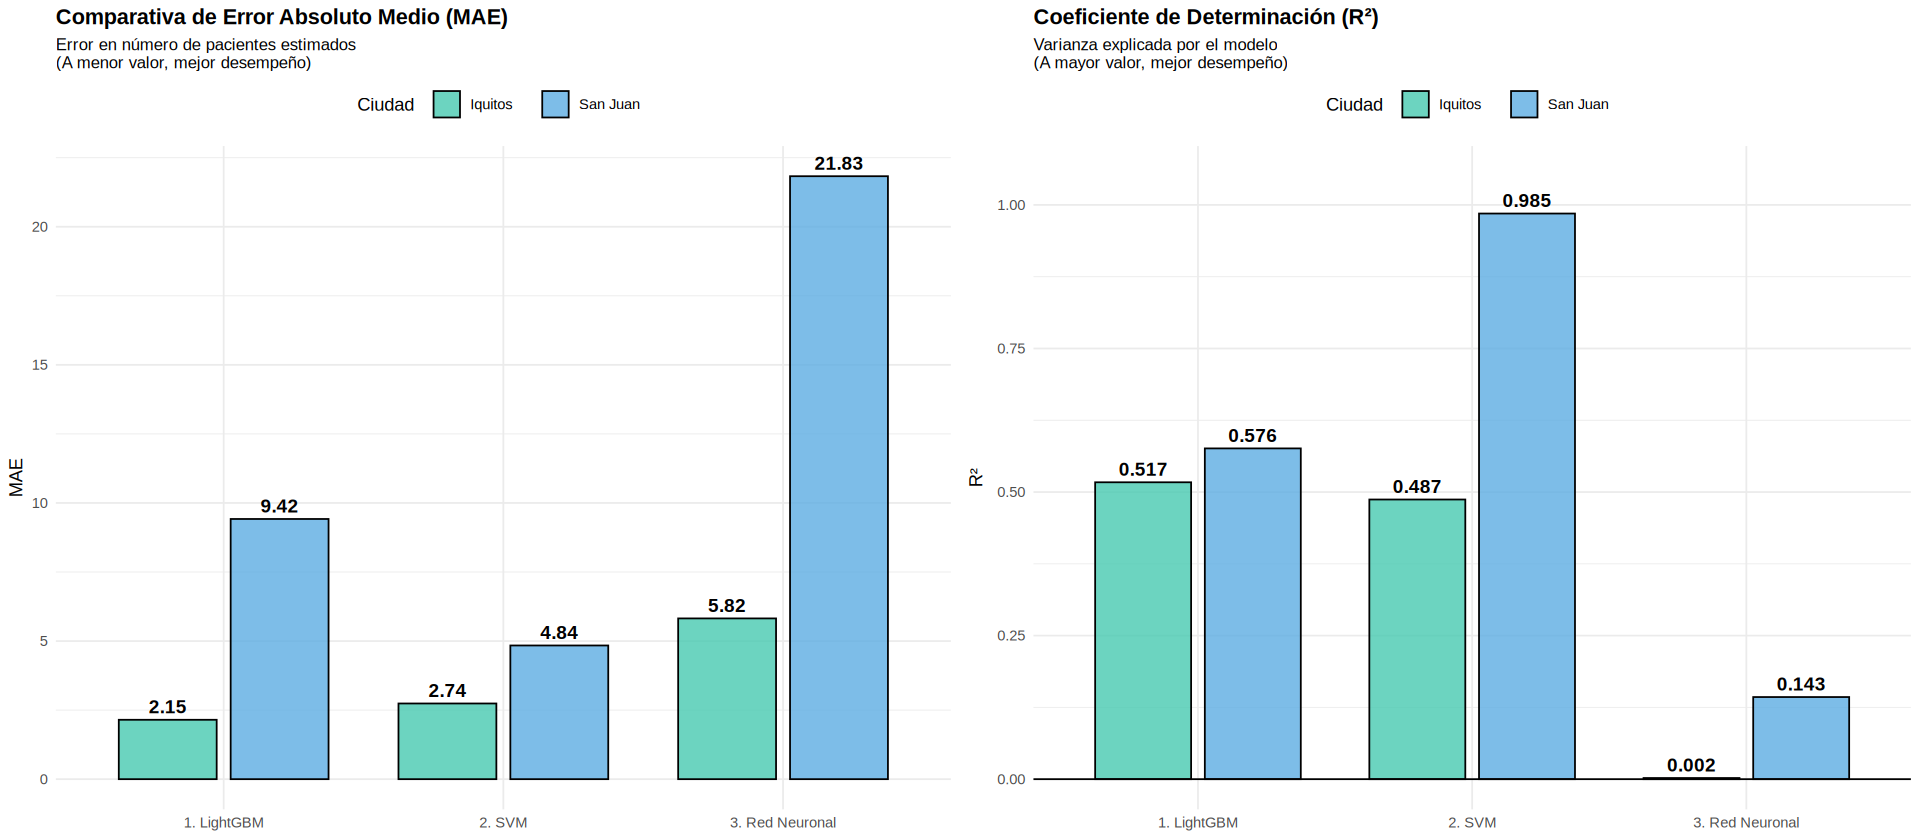

In [23]:
# --- 1. Funciones auxiliares para métricas ---
calc_mae <- function(real, pred) { round(mean(abs(real - pred)), 2) }
calc_r2 <- function(real, pred) {
  tss <- sum((real - mean(real))^2)
  rss <- sum((real - pred)^2)
  r2 <- 1 - (rss/tss)
  return(round(max(0, r2), 3)) # Evitar R2 negativos artificiales
}

# --- 2. Predicciones internas finales ---
# LightGBM
p_lgb_sj <- predict(modelo_sj, as.matrix(train_sj[, ..features_lgb]))
p_lgb_iq <- predict(modelo_iq, as.matrix(train_iq[, ..features_lgb]))

# SVM
p_svm_sj <- pred_train_svm_sj
p_svm_iq <- pred_train_svm_iq

# Red Neuronal
p_nn_sj <- pred_train_sj_real
p_nn_iq <- pred_train_iq_real

# Reales
y_sj <- train_sj$total_cases
y_iq <- train_iq$total_cases

# --- 3. Recopilar métricas en DataFrames ---
df_resultados <- data.frame(
  Modelo = rep(c("1. LightGBM", "2. SVM", "3. Red Neuronal"), each = 2),
  Ciudad = rep(c("San Juan", "Iquitos"), times = 3),
  MAE = c(calc_mae(y_sj, p_lgb_sj), calc_mae(y_iq, p_lgb_iq),
          calc_mae(y_sj, p_svm_sj), calc_mae(y_iq, p_svm_iq),
          calc_mae(y_sj, p_nn_sj), calc_mae(y_iq, p_nn_iq)),
  R2 = c(calc_r2(y_sj, p_lgb_sj), calc_r2(y_iq, p_lgb_iq),
         calc_r2(y_sj, p_svm_sj), calc_r2(y_iq, p_svm_iq),
         calc_r2(y_sj, p_nn_sj), calc_r2(y_iq, p_nn_iq))
)

# Imprimir tabla resumen en consola
cat("\n--- Tabla Resumen de Métricas (Train Set) ---\n")
print(df_resultados)
cat("\n")

# --- 4. Generación de Gráficos ---
options(repr.plot.width = 16, repr.plot.height = 7)

# Gráfico 1: MAE
plot_mae <- ggplot(df_resultados, aes(x = Modelo, y = MAE, fill = Ciudad)) +
  geom_bar(stat = "identity", position = position_dodge(width = 0.8), width = 0.7, color = "black", alpha = 0.8) +
  geom_text(aes(label = MAE), vjust = -0.5, position = position_dodge(width = 0.8), size = 4, fontface = "bold") +
  labs(title = "Comparativa de Error Absoluto Medio (MAE)",
       subtitle = "Error en número de pacientes estimados\n(A menor valor, mejor desempeño)",
       y = "MAE") +
  theme_minimal() +
  scale_fill_manual(values = c("San Juan" = "#5DADE2", "Iquitos" = "#48C9B0")) +
  theme(plot.title = element_text(face = "bold", size = 13),
        plot.subtitle = element_text(size = 10),
        legend.position = "top", axis.title.x = element_blank())

# Gráfico 2: R2
plot_r2 <- ggplot(df_resultados, aes(x = Modelo, y = R2, fill = Ciudad)) +
  geom_bar(stat = "identity", position = position_dodge(width = 0.8), width = 0.7, color = "black", alpha = 0.8) +
  geom_text(aes(label = R2), vjust = -0.5, position = position_dodge(width = 0.8), size = 4, fontface = "bold") +
  geom_hline(yintercept = 0) +
  scale_y_continuous(limits = c(min(0, min(df_resultados$R2)), 1.05)) +
  labs(title = "Coeficiente de Determinación (R²)",
       subtitle = "Varianza explicada por el modelo\n(A mayor valor, mejor desempeño)",
       y = "R²") +
  theme_minimal() +
  scale_fill_manual(values = c("San Juan" = "#5DADE2", "Iquitos" = "#48C9B0")) +
  theme(plot.title = element_text(face = "bold", size = 13),
        plot.subtitle = element_text(size = 10),
        legend.position = "top", axis.title.x = element_blank())

# Renderizar ambos gráficos lado a lado
grid.arrange(plot_mae, plot_r2, ncol = 2)

Para facilitar la interpretación de los modelos entrenados, recopilamos las métricas de Error Absoluto Medio (MAE) obtenidas
durante la validación interna. A continuación, se presenta una tabla consolidada y un gráfico de barras comparativo que
contrasta el rendimiento de los ensambles de árboles (LightGBM), las máquinas de vectores de soporte (SVM) y las redes
neuronales (Torch) en los distintos biomas de San Juan e Iquitos.


--- Tabla Resumen de MAE Interno ---
           Modelo   Ciudad       MAE
1     1. LightGBM San Juan  9.423969
2     1. LightGBM  Iquitos  2.151001
3          2. SVM San Juan  4.838415
4          2. SVM  Iquitos  2.740591
5 3. Red Neuronal San Juan 21.827989
6 3. Red Neuronal  Iquitos  5.816841



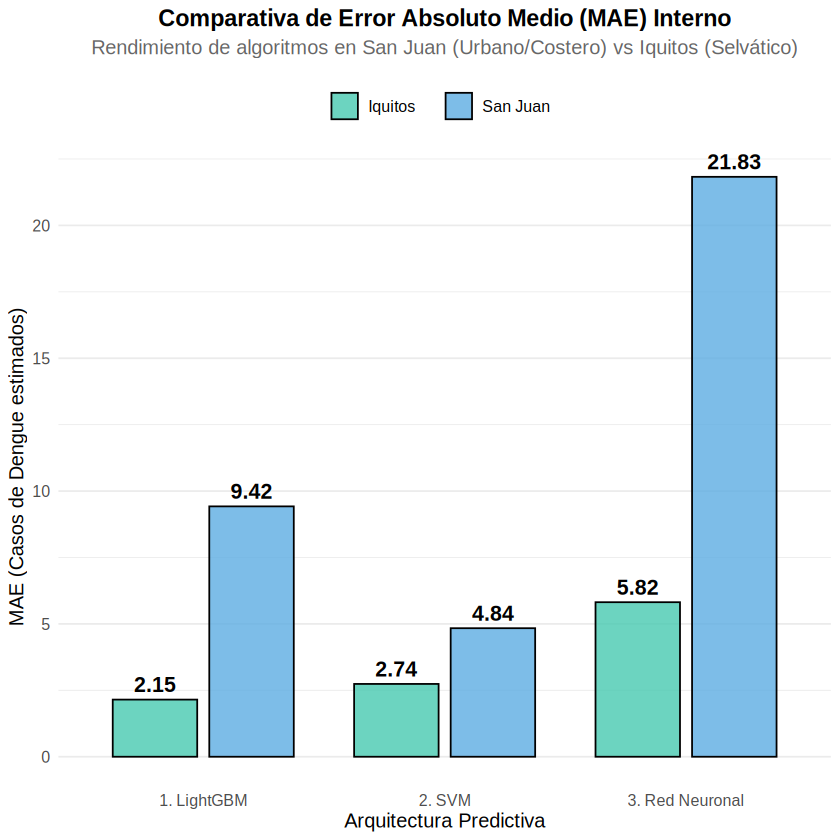

In [22]:
# 1. Recopilar los MAEs calculados previamente en el entorno de trabajo
mae_lgb_sj <- mean(abs(train_sj$total_cases - predict(modelo_sj, as.matrix(train_sj[, ..features_lgb]))))
mae_lgb_iq <- mean(abs(train_iq$total_cases - predict(modelo_iq, as.matrix(train_iq[, ..features_lgb]))))

mae_svm_sj <- mean(abs(train_sj$total_cases - pred_train_svm_sj))
mae_svm_iq <- mean(abs(train_iq$total_cases - pred_train_svm_iq))

mae_nn_sj  <- mean(abs(train_sj$total_cases - pred_train_sj_real))
mae_nn_iq  <- mean(abs(train_iq$total_cases - pred_train_iq_real))

# 2. Crear un Data Frame estructurado con los resultados
df_resultados <- data.frame(
  Modelo = rep(c("1. LightGBM", "2. SVM", "3. Red Neuronal"), each = 2),
  Ciudad = rep(c("San Juan", "Iquitos"), times = 3),
  MAE = c(mae_lgb_sj, mae_lgb_iq, mae_svm_sj, mae_svm_iq, mae_nn_sj, mae_nn_iq)
)

# 3. Mostrar la tabla resumen en consola
cat("\n--- Tabla Resumen de MAE Interno ---\n")
print(df_resultados)
cat("\n")

# 4. Generar y renderizar el gráfico de barras comparativo
grafico_comparativo <- ggplot(df_resultados, aes(x = Modelo, y = MAE, fill = Ciudad)) +
  geom_bar(stat = "identity", position = position_dodge(width = 0.8), width = 0.7, color="black", alpha=0.8) +
  geom_text(aes(label = round(MAE, 2)), vjust = -0.5, position = position_dodge(width = 0.8), size = 4.5, fontface="bold") +
  labs(title = "Comparativa de Error Absoluto Medio (MAE) Interno",
       subtitle = "Rendimiento de algoritmos en San Juan (Urbano/Costero) vs Iquitos (Selvático)",
       x = "Arquitectura Predictiva",
       y = "MAE (Casos de Dengue estimados)") +
  theme_minimal() +
  scale_fill_manual(values = c("San Juan" = "#5DADE2", "Iquitos" = "#48C9B0")) +
  theme(
    text = element_text(size = 12),
    plot.title = element_text(face = "bold", hjust = 0.5, size=14),
    plot.subtitle = element_text(hjust = 0.5, color = "gray40", margin=margin(b=15)),
    legend.position = "top",
    legend.title = element_blank(),
    panel.grid.major.x = element_blank()
  )

# Imprimir gráfico en pantalla
print(grafico_comparativo)

---

## 9. Referencias Bibliográficas


*   **DrivenData (2016).** *DengAI: Predicting Disease Spread.* Competición pública que provee el *dataset* originado por la *Predict the Next Pandemic Initiative* (CDC y NOAA).
*   **Estévez, L. et al. (2020).** *Influencia del cambio climático en la biología de Aedes aegypti y su impacto en la transmisión del dengue.* Revista de Biología Tropical.
*   **Géron, A. (2019).** *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow.* O'Reilly Media, Inc. (Referencia para optimización bayesiana y regularización L2/Dropout).
*   **Ke, G. et al. (2017).** *LightGBM: A Highly Efficient Gradient Boosting Decision Tree.* Advances in Neural Information Processing Systems 30.
*   **Liu, Z. et al. (2023).** *The effect of temperature on dengue virus transmission by Aedes mosquitoes.* Frontiers in Cellular and Infection Microbiology. (Justificación del Período de Incubación Extrínseco y los *lags* temporales).
*   **Meza-Ballesta, A. y Gónima, L. (2014).** *Influencia del clima y de la cobertura vegetal en la ocurrencia del Dengue (2001-2010).* Revista de Salud Pública.
*   **Mussumeci, E. y Coelho, F. C. (2020).** *Large-scale multivariate forecasting models for Dengue-LSTM versus random forest, SVM, MIR, and SARIMA.* Memórias do Instituto Oswaldo Cruz. (Justificación del procesamiento de latencias no lineales).
*   **R Core Team (2025).** *R: A Language and Environment for Statistical Computing.* R Foundation for Statistical Computing. (Entorno de programación base).
*   **Raschka, S. y Mirjalili, V. (2019).** *Python Machine Learning.* Packt Publishing Ltd. (Referencia teórica de Support Vector Machines y funciones Kernel RBF).
*   **Reinhold, J. M., Lazzari, C. R., y Lahondère, C. (2018).** *Effects of the environmental temperature on Aedes aegypti and Aedes albopictus mosquitoes: a review.* Insects.
*   **Sánchez-Lara, E. et al. (2022).** *Variabilidad climática y su influencia en la aparición del dengue en provincia Guantánamo.* Revista Información Científica.

> *Los paquetes estadísticos implementados (`data.table`, `zoo`, `lightgbm`, `e1071`, `rBayesianOptimization`, `ggplot2`) y la arquitectura de Deep Learning nativa para R (`torch`, `luz`) corresponden a sus respectivas distribuciones de código abierto en CRAN.*